Ячейка 1 (Загрузка и сборка):

In [2]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
from src.series import build_series, plot_series_smoothing, decompose_series, find_outliers_and_changepoints

# Загружаем данные
df = pd.read_parquet('../data/processed/cleanfull.parquet')

# Собираем ряд по дням (D)
series = build_series(df, 'day', freq='D')
print(f"Всего периодов (дней): {len(series)}")
print(f"Пустых периодов (нулевых записей): {(series == 0).sum()}")

Всего периодов (дней): 181
Пустых периодов (нулевых записей): 0


Ячейка 2 (График сглаживания):

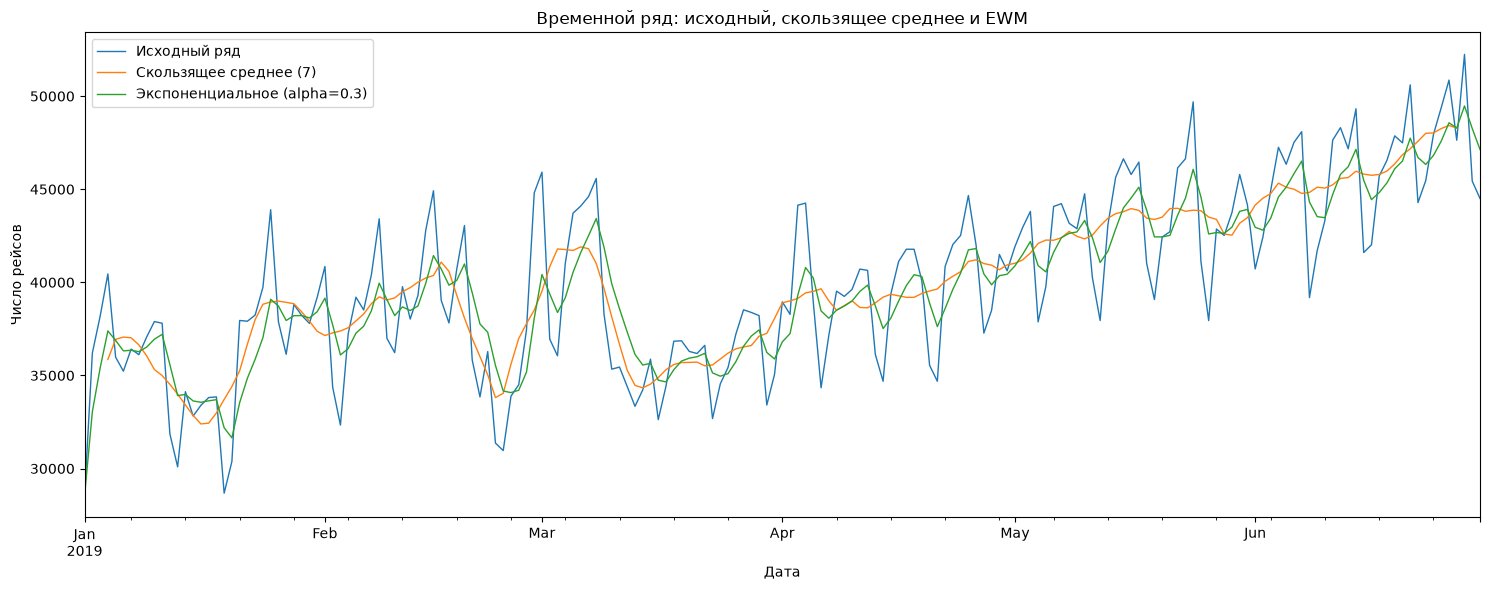

In [3]:
smooth_df = plot_series_smoothing(series)

Ячейка 3 (Декомпозиция):

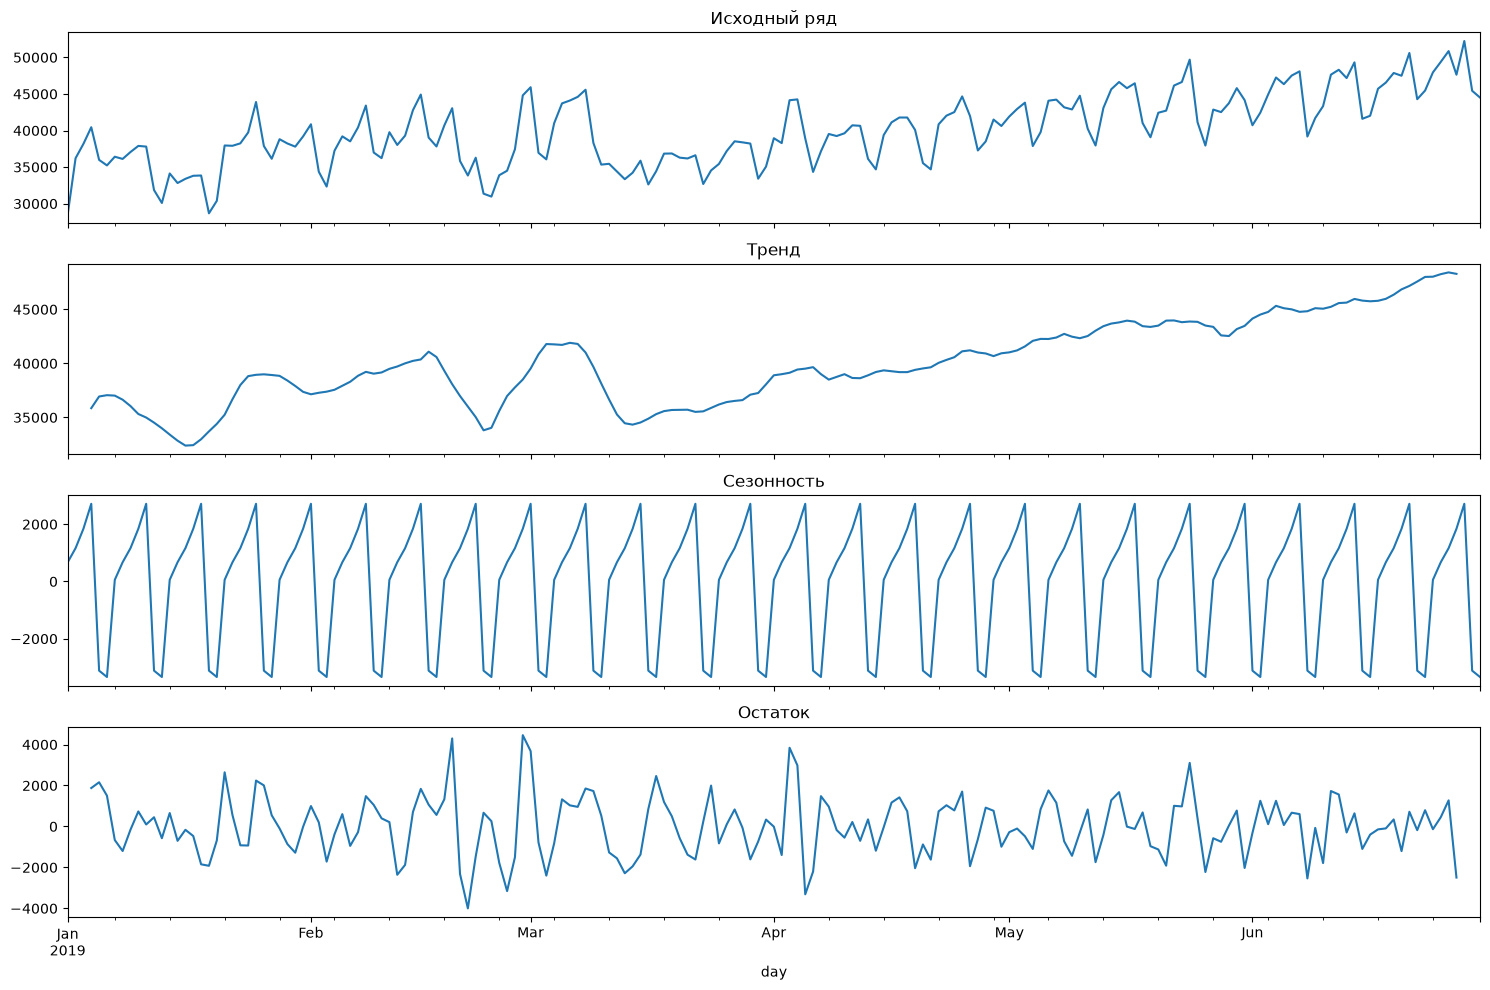

In [4]:
# Сезонность берем 7 (дней), так как у нас дневной ряд и недельный цикл
parts = decompose_series(series, period=7)

Ячейка 4 (Выбросы и переломы):

In [5]:
outliers, changepoints = find_outliers_and_changepoints(parts, window=7)

Найдено выбросов по остатку: 2
Периоды выбросов: [Timestamp('2019-02-19 00:00:00+0000', tz='UTC'), Timestamp('2019-02-28 00:00:00+0000', tz='UTC')]...

Кандидаты в точки перелома:
  2019-03-10 00:00:00+00:00: разность средних = 5909.96
  2019-03-11 00:00:00+00:00: разность средних = 5793.37
  2019-03-09 00:00:00+00:00: разность средних = 5391.55


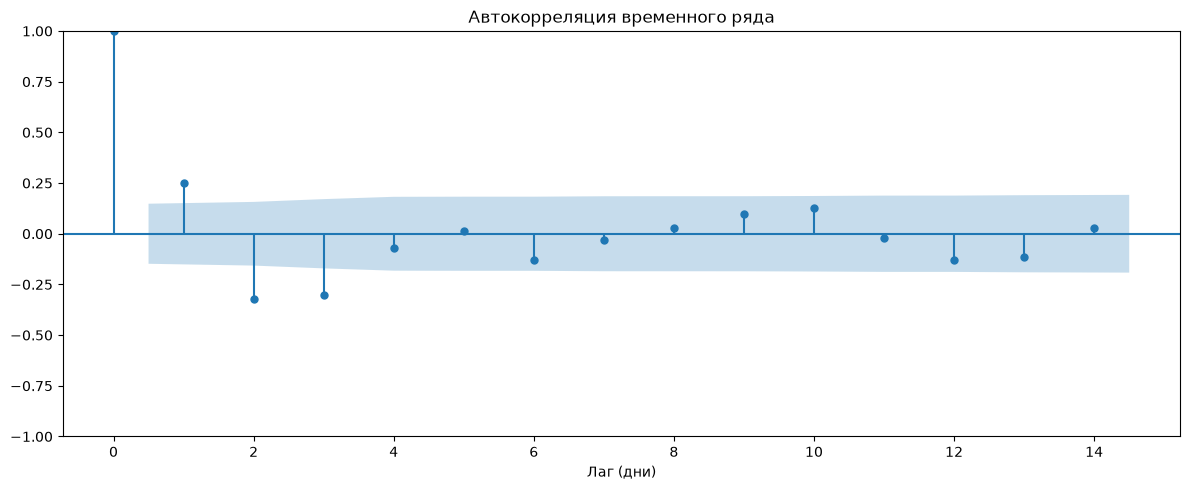

Лаг с наибольшей автокорреляцией: 1 (значение: 0.252)


In [6]:
from src.series import plot_autocorrelation

# Считаем автокорреляцию по остатку (без тренда)
resid_series = parts.resid.dropna()
best_lag, best_val = plot_autocorrelation(resid_series)

### Таблица 4 - Параметры ряда

| Показатель | Значение |
| :--- | :--- |
| Величина ряда и период агрегации | 181 |
| Число периодов, из них пустых | 0 |
| Окно скользящего среднего | 7 дней |
| Период сезонности | 7 (недельная) |
| Лаг с наибольшей автокорреляцией и её значение | 1 (значение: 0.252) |
| Выбросы по остатку: число и периоды | 2 [Timestamp('2019-02-19 00:00:00+0000', tz='UTC'), Timestamp('2019-02-28 00:00:00+0000', tz='UTC')] |
| Точки перелома и их объяснение | 2019-03-10 00:00:00+00:00: разность средних = 5909.96, 2019-03-11 00:00:00+00:00: разность средних = 5793.37, 2019-03-09 00:00:00+00:00: разность средних = 5391.55 |

Вывод: «Временной ряд охватывает 181 дней без пустых периодов. Декомпозиция выявила недельную сезонность (период 7). Автокорреляция остатков имеет пик на лаге 1 (значение: 0.252), что подтверждает наличие недельного цикла. Найдено 2 выброса (19 и 28 февраля 2019 г.). Основной кандидат в точку перелома — начало марта 2019 года, где среднее значение ряда изменилось на ~5909 рейсов. Это может быть связано с сезонными изменениями или особенностями сбора данных.»